<a href="https://colab.research.google.com/github/shailshree23/ML2_Lab/blob/main/SelfOrganisingMaps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install minisom

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=ebb5aab5561510355f5714652cfd2b8a8c58081e7e52b9a22a2dc2ebc8ecb9bb
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

In [3]:
# Load the dataset
wine = load_wine()

# Convert dataset into a DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)

print("\nDataset Description:")
print(df.describe())

First five rows of the dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset Shape: (178, 13)

Dataset Description:
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859          

In [4]:
# Normalize the data between 0 and 1
scaler = MinMaxScaler()

data_scaled = scaler.fit_transform(df)

print("Normalized Dataset:")
print(data_scaled[:5])

print("\nShape of normalized data:", data_scaled.shape)

Normalized Dataset:
[[0.84210526 0.1916996  0.57219251 0.25773196 0.61956522 0.62758621
  0.57383966 0.28301887 0.59305994 0.37201365 0.45528455 0.97069597
  0.56134094]
 [0.57105263 0.2055336  0.4171123  0.03092784 0.32608696 0.57586207
  0.51054852 0.24528302 0.27444795 0.26450512 0.46341463 0.78021978
  0.55064194]
 [0.56052632 0.3201581  0.70053476 0.41237113 0.33695652 0.62758621
  0.61181435 0.32075472 0.75709779 0.37542662 0.44715447 0.6959707
  0.64693295]
 [0.87894737 0.23913043 0.60962567 0.31958763 0.4673913  0.98965517
  0.66455696 0.20754717 0.55835962 0.55631399 0.30894309 0.7985348
  0.85734665]
 [0.58157895 0.36561265 0.80748663 0.53608247 0.52173913 0.62758621
  0.49578059 0.49056604 0.44479495 0.25938567 0.45528455 0.60805861
  0.32596291]]

Shape of normalized data: (178, 13)


In [5]:
# Define SOM grid dimensions
som_rows = 10
som_cols = 10

# Initialize SOM
som = MiniSom(
    x=som_rows,
    y=som_cols,
    input_len=data_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights randomly
som.random_weights_init(data_scaled)

print("SOM model initialized successfully!")

SOM model initialized successfully!


In [6]:
# Train SOM
num_iterations = 10000

som.train_random(
    data_scaled,
    num_iterations,
    verbose=True
)

print("\nSOM training completed!")

 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 0.17198808181343903

SOM training completed!


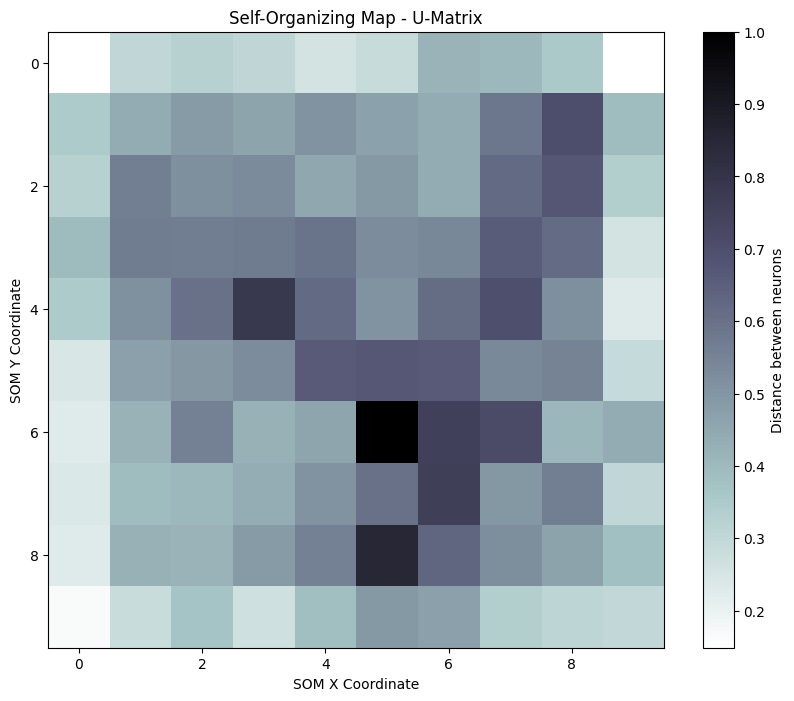

In [7]:
plt.figure(figsize=(10, 8))

plt.imshow(
    som.distance_map().T,
    cmap='bone_r',
    interpolation='nearest'
)

plt.colorbar(label='Distance between neurons')

plt.title("Self-Organizing Map - U-Matrix")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")

plt.show()

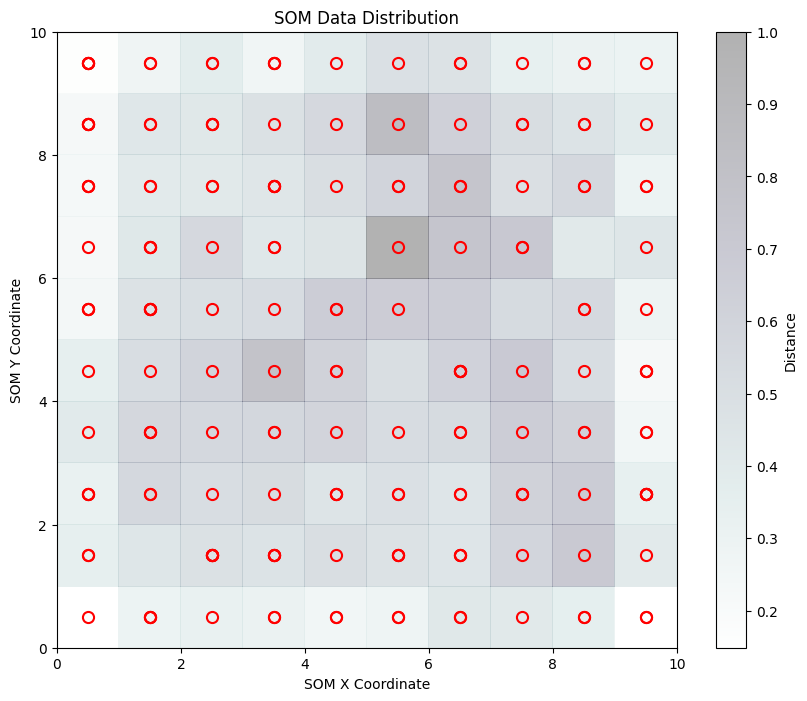

In [8]:
plt.figure(figsize=(10, 8))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r',
    alpha=0.3
)

plt.colorbar(label='Distance')

# Plot each data sample
for i, sample in enumerate(data_scaled):

    x, y = som.winner(sample)

    plt.plot(
        x + 0.5,
        y + 0.5,
        'o',
        markerfacecolor='None',
        markeredgecolor='red',
        markersize=8,
        markeredgewidth=1.5
    )

plt.title("SOM Data Distribution")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")

plt.show()

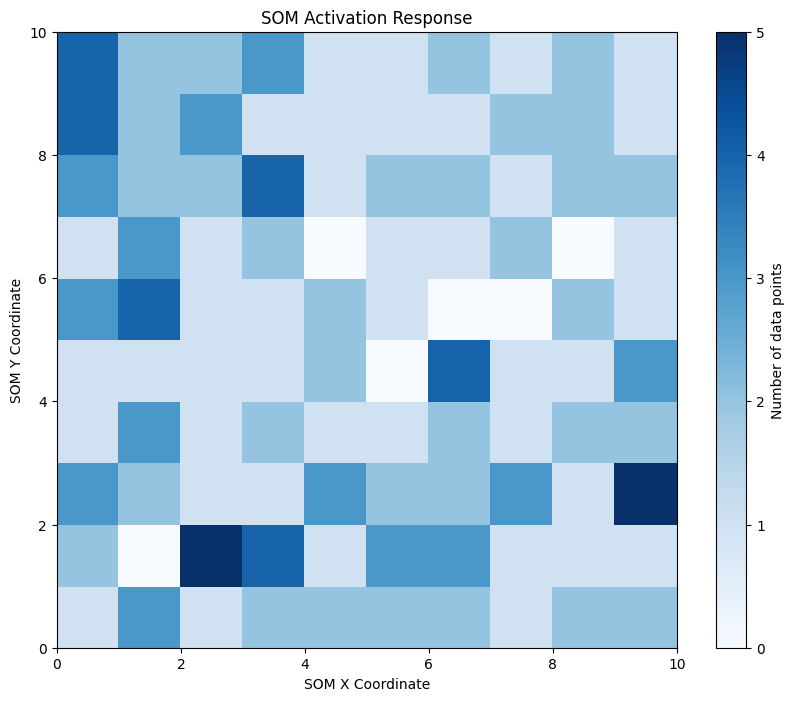

In [9]:
plt.figure(figsize=(10, 8))

plt.pcolor(
    som.activation_response(data_scaled).T,
    cmap='Blues'
)

plt.colorbar(label='Number of data points')

plt.title("SOM Activation Response")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")

plt.show()

In [10]:
# Store the BMU coordinates
bmu_coordinates = []

for sample in data_scaled:

    winner = som.winner(sample)

    bmu_coordinates.append(winner)

# Create result DataFrame
results = df.copy()

results['SOM_X'] = [x for x, y in bmu_coordinates]
results['SOM_Y'] = [y for x, y in bmu_coordinates]

print("SOM Mapping Results:")
display(results.head(10))

# Save results
results.to_csv("SOM_Results.csv", index=False)

print("Results saved successfully!")

SOM Mapping Results:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,SOM_X,SOM_Y
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,9
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1,6
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,3,6
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1,9
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,5,7
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,2,8
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,7
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,3,8
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,7
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,8


Results saved successfully!
